# GraphST Benchmarking

- Creator: Sebastian Birk (<sebastian.birk@helmholtz-munich.de>)
- Date of Creation: 11.01.2023
- Date of Last Modification: 05.04.2026 (Sebastian Birk; <sebastian.birk@helmholtz-munich.de>)

- Run the first part of this notebook in the graphst uv environment, installable from ```../../envs/graphst.sh```
- Run the second part of this notebook in the nichecompass uv environment, installable from ```../../envs/nichecompass.sh```
- The GraphST source code is available at https://github.com/JinmiaoChenLab/GraphST.
- The corresponding preprint is "Long, Y. et al. DeepST: A versatile graph contrastive learning framework for spatially informed clustering, integration, and deconvolution of spatial transcriptomics. Preprint at https://doi.org/10.1101/2022.08.02.502407".
- The workflow of this notebook follows the tutorial from https://deepst-tutorials.readthedocs.io/en/latest/Tutorial%204_Horizontal%20Integration.html.

## 1. Setup

### 1.1 Load Libraries

In [1]:
import sys
sys.path.append("../../utils")

In [2]:
import time

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import os
import warnings
import torch
import pandas as pd
import scanpy as sc
import multiprocessing as mp
import matplotlib.pyplot as plt
import sklearn.metrics as skm
import squidpy as sq
try:
    from GraphST import GraphST
    import paste as pst
    import ot
except:
    from scib_metrics import ilisi_knn
    from scib_metrics.nearest_neighbors import pynndescent
from matplotlib import gridspec
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

from analysis_utils import *

/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


### 1.2 Configure Paths

In [3]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [4]:
method = 'graphst'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# GraphST params
emb_key = 'emb'

# Cluster params
latent_leiden_resolution = 1.5

### 1.3 Run Notebook Setup

In [5]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [6]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [7]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [8]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

/tmp/ipykernel_3730328/3043166597.py:3: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(


In [9]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

### 1.5 Define Functions

In [10]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [11]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

In [12]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs,
                             radius,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs,
                             radius,
                             delaunay,
                             include_self_loop,
                             batch_key=None,
                             compute_neighbor_counts=False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. Analysis

### 2.1 Retrieve Embeddings

In [13]:
# Run device. By default, the package is implemented on 'cpu'. It is recommended to use GPU.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [14]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('.h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('.h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_3730328/2029220626.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [15]:
adata_tmp = adata.copy()

/tmp/ipykernel_3708926/863037477.py:4: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  adata_list[0].obsm['spatial'] = coords0
/tmp/ipykernel_3708926/863037477.py:13: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  a.obsm['spatial'] = coords


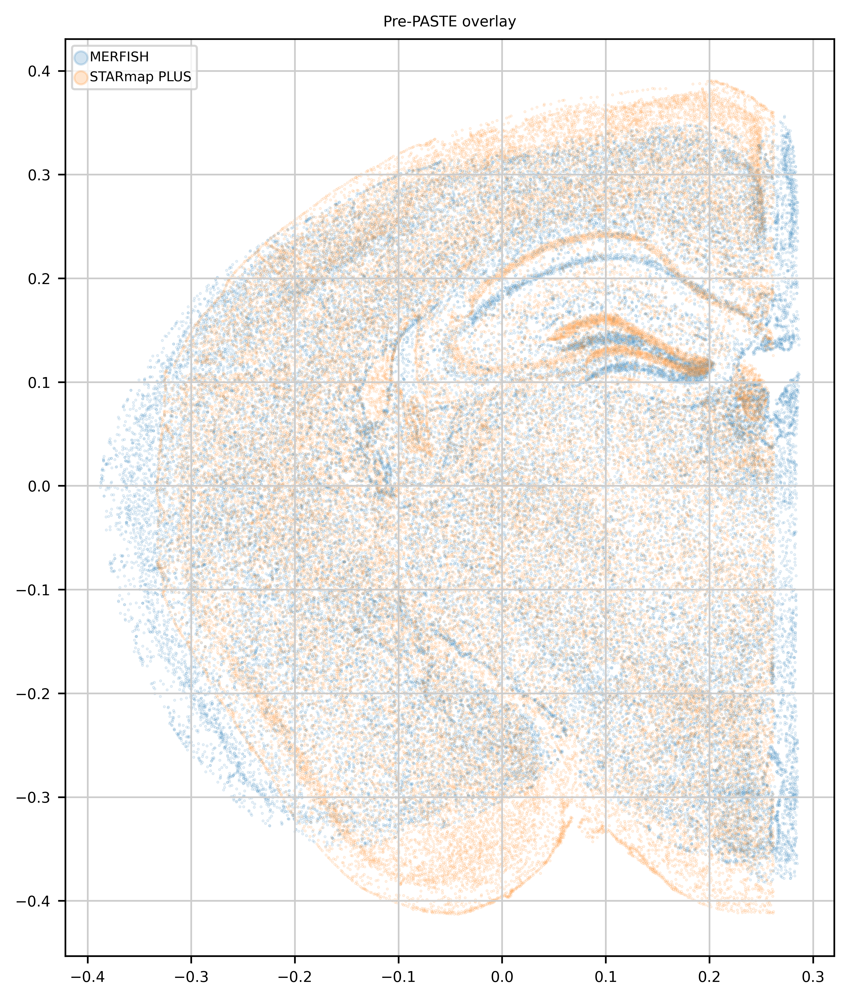

In [15]:
# ── 1. Flip MERFISH y-axis (raw coords have inverted y) ──
coords0 = adata_list[0].obsm['spatial'].copy().astype(float)
coords0[:, 1] = -coords0[:, 1]
adata_list[0].obsm['spatial'] = coords0

# ── 2. Center and normalize both to unit diagonal ──
for a in adata_list:
    coords = a.obsm['spatial'].copy().astype(float)
    coords -= coords.mean(axis=0)
    diag = np.sqrt((coords[:, 0].max() - coords[:, 0].min())**2 +
                   (coords[:, 1].max() - coords[:, 1].min())**2)
    coords /= diag
    a.obsm['spatial'] = coords

# ── 3. Rotate and flip ──
def apply_rotation(coords, angle_deg, flip=None):
    x, y = coords[:, 0], coords[:, 1]
    theta = np.radians(angle_deg)
    x_rot = x * np.cos(theta) - y * np.sin(theta)
    y_rot = x * np.sin(theta) + y * np.cos(theta)
    if flip == 'x':
        x_rot = -x_rot
    elif flip == 'y':
        y_rot = -y_rot
    return np.column_stack([x_rot, y_rot])

adata_list[0].obsm['spatial'] = apply_rotation(adata_list[0].obsm['spatial'], 180, flip='x')
adata_list[1].obsm['spatial'] = apply_rotation(adata_list[1].obsm['spatial'], 270)

# ── 4. Verify overlay ──
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['tab:blue', 'tab:orange']
labels = ['MERFISH', 'STARmap PLUS']
for i, a in enumerate(adata_list):
    c = a.obsm['spatial']
    ax.scatter(c[:, 0], c[:, 1], s=0.1, alpha=0.2, c=colors[i], label=labels[i])
ax.set_aspect('equal')
ax.legend(markerscale=20)
ax.set_title('Pre-PASTE overlay')
plt.show()

In [ ]:
# ── 5. Run PASTE alignment ──
start_time = time.time()
pi = pst.pairwise_align(
    adata_list[0], adata_list[1],
    alpha=0.05,
    numItermax=200000,
    use_gpu=False
)
adata_list = pst.stack_slices_pairwise(adata_list, [pi])
adata = ad.concat(adata_list, join="inner")
elapsed_time = time.time() - start_time
print(f"PASTE alignment done in {elapsed_time:.1f}s")

In [ ]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

In [ ]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

In [ ]:
# define model
model = GraphST.GraphST(adata, device=device)

# run model
adata = model.train()

In [ ]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

In [16]:
adata = sc.read_h5ad((f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad'))

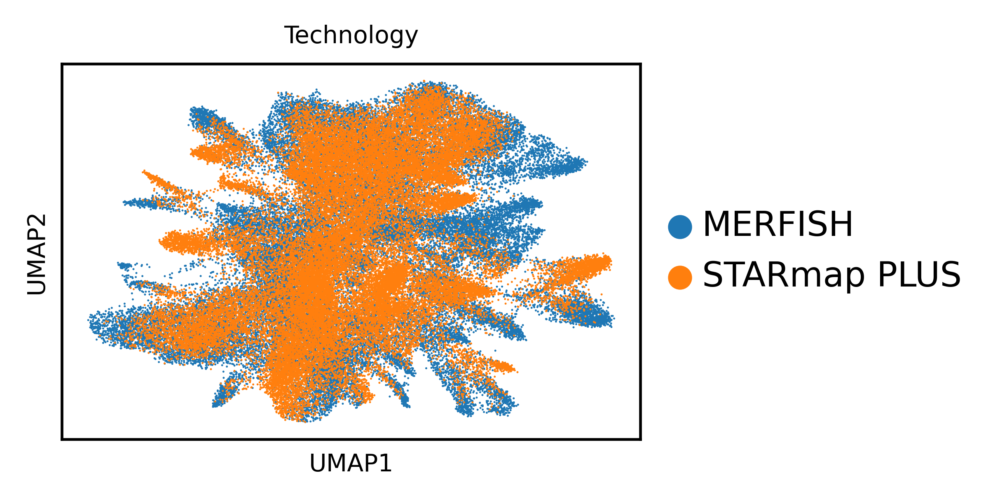

/tmp/ipykernel_3618562/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


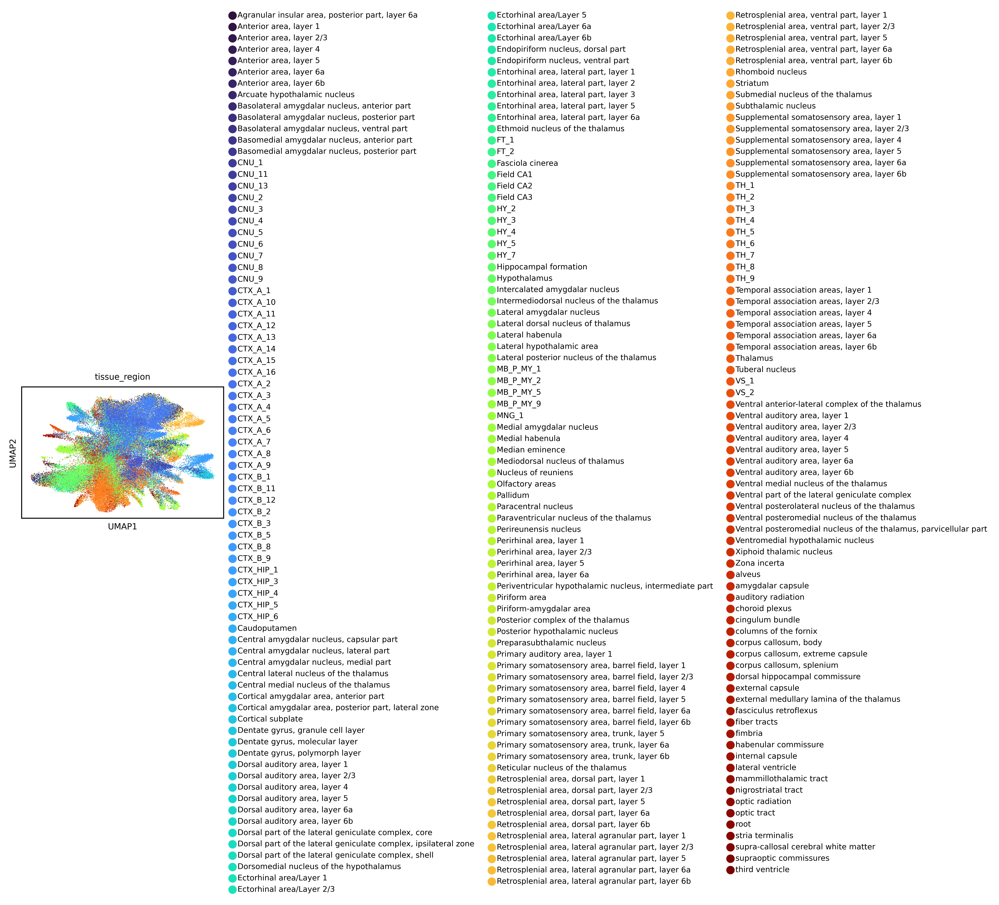

In [17]:
try:
    rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                     n_pcs=n_pcs, key_added=emb_key)
    rsc.tl.umap(adata, neighbors_key=emb_key)
except NameError:
    sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                    n_pcs=n_pcs, key_added=emb_key)
    sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [20]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

Change environment to nichecompass uv env here!

In [16]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

In [17]:
# Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

try:
    rsc.tl.leiden(adata,
                  neighbors_key=emb_key,
                  key_added=latent_cluster_key,
                  resolution=latent_leiden_resolution,
                  flavor="igraph",
                  n_iterations=2
                 )
except NameError:
    sc.tl.leiden(adata,
                 neighbors_key=emb_key,
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution,
                 flavor="igraph",
                 n_iterations=2
                )

In [18]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
emb_clusters_res_1.5
19    7885
8     7773
10    6452
11    5573
15    5364
6     5083
9     4629
3     4353
21    4049
23    3574
27    3332
7     3063
0     2709
2     2654
16    2429
25    2085
5     1840
4     1707
14    1440
13    1279
18    1268
12    1268
1     1131
24     966
22     936
26     815
17     787
28     458
29     431
20     371
Name: count, dtype: int64


In [32]:
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded_clustered.h5ad')

In [16]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/graphst/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
adata_tmp.obs[latent_cluster_key] = adata.obs[latent_cluster_key]
adata_tmp.obs[batch_key] = adata.obs[batch_key]
adata_tmp.obsm[emb_key] = adata.obsm[emb_key]
adata_tmp.uns[emb_key] = adata.uns[emb_key]
adata_tmp.obsp = adata.obsp

/tmp/ipykernel_3730328/2489520453.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


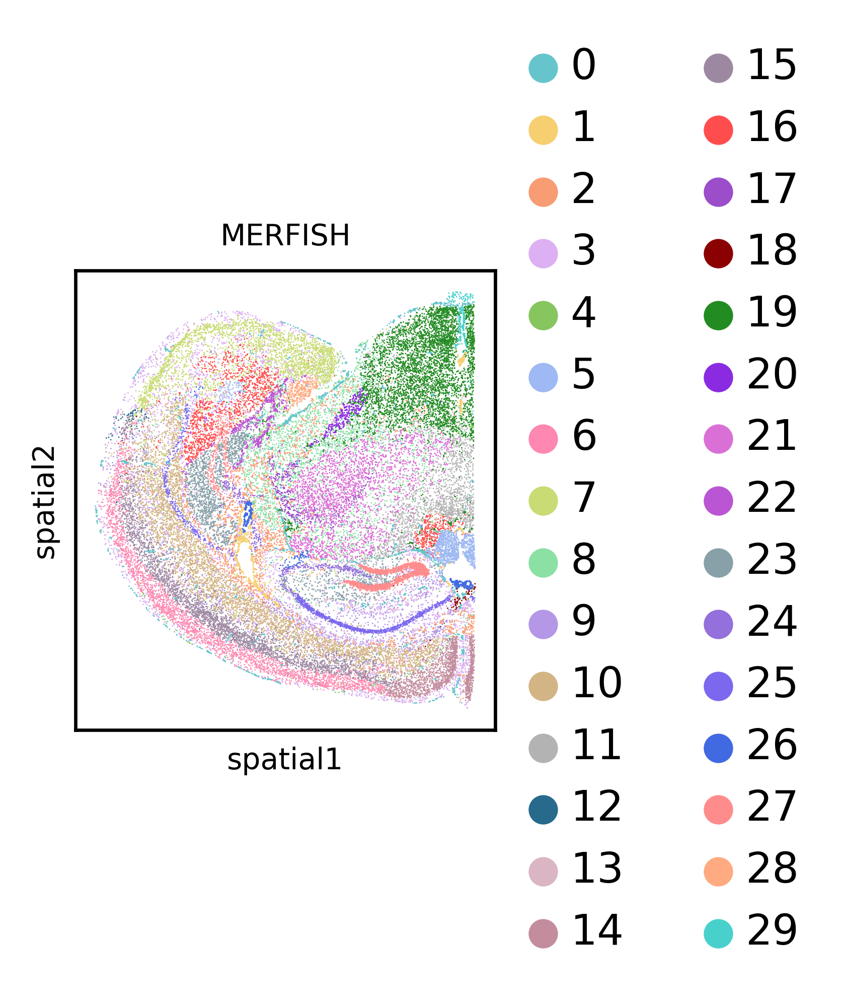

/tmp/ipykernel_3730328/2489520453.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


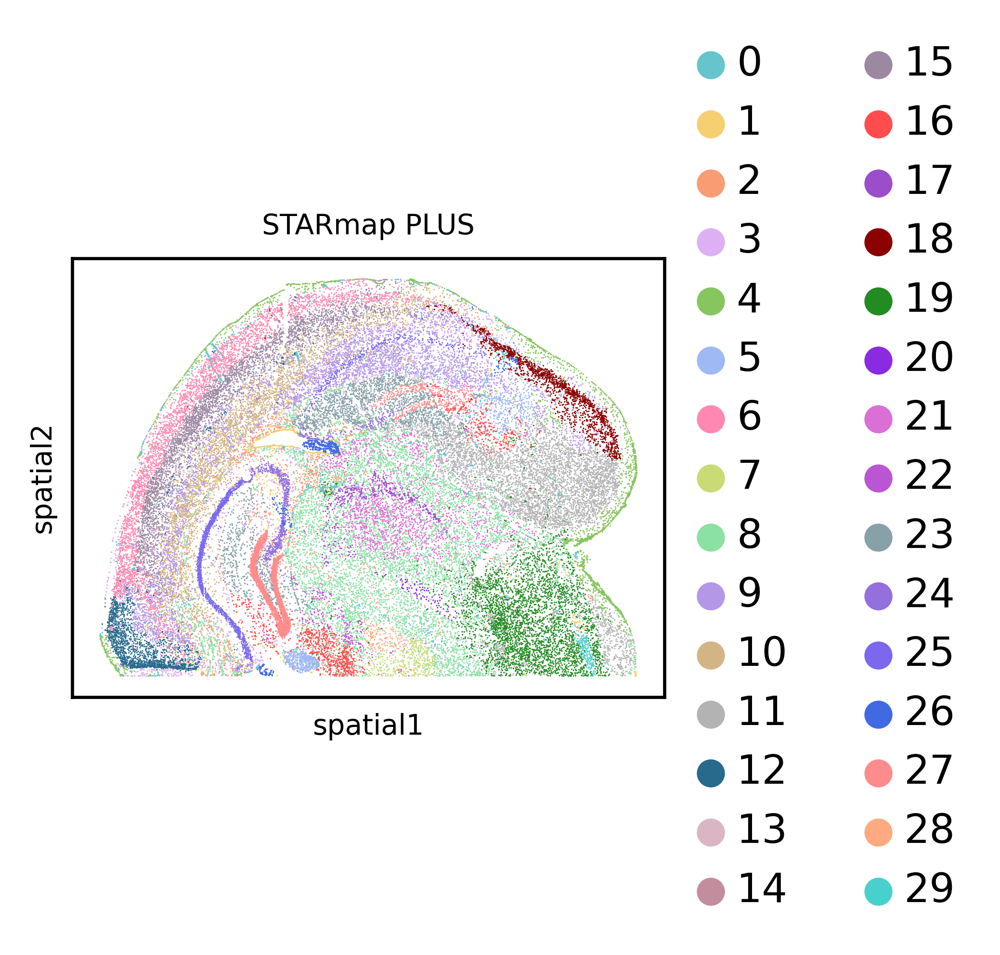

In [18]:
samples = adata_tmp.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata_tmp[adata_tmp.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [19]:
# Compute average cosine similarity of embeddings
X = adata_tmp.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

emb average cosine similarity: 0.40424638986587524
Saved → /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/graphst/mmb0-1b_smb1-1b_1p_emb_avg_cosine_similarity.csv


In [20]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata_tmp.obs[region_key].notna()
    labels_true = adata_tmp.obs.loc[mask, region_key]
    labels_pred = adata_tmp.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.5400
ARI (Sub_molecular_tissue_region): 0.2882
NMI (ccf_region_name): 0.5073
ARI (ccf_region_name): 0.1839


In [21]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata_tmp.obs[batch_key].values
knn = pynndescent(adata_tmp.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata_tmp.obsm[emb_key],
    adata_tmp.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata_tmp, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


iLISI: 0.4834
ASW batch: 0.0290
MMD: 0.0412


In [25]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata_tmp,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata_tmp,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata_tmp.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata_tmp.obs[region_key].notna()
        labels_true = adata_tmp.obs.loc[mask, region_key]
        labels_pred = adata_tmp.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.6  (16 clusters) ──
  Sub_molecular_tissue_region               NMI=0.4950  ARI=0.2081
  ccf_region_name                           NMI=0.4579  ARI=0.1092

── Resolution 0.7  (17 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5021  ARI=0.2151
  ccf_region_name                           NMI=0.4701  ARI=0.1229

── Resolution 0.8  (19 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5274  ARI=0.2551
  ccf_region_name                           NMI=0.4817  ARI=0.1343

── Resolution 0.9  (22 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5273  ARI=0.2430
  ccf_region_name                           NMI=0.4848  ARI=0.1471

── Resolution 1.0  (24 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5431  ARI=0.2806
  ccf_region_name                           NMI=0.4946  ARI=0.1575

── Resolution 1.1  (26 clusters) ──
  Sub_molecular_tissue_region               NMI=0.5375  ARI=0.2762
  ccf_region_name                        